# AI-Based Crop-Safe Path Planning for an Autonomous Potato-Field Robot
**Artificial Intelligence – Group Coding Assignment | Group XX**

A robot has to travel from a start cell to a destination in a potato field without damaging plants. We model the field as a grid, plan routes with BFS, DFS, Greedy Best-First and A*, add a penalty for passing too close to protected crops, and simulate obstacles that the robot only discovers while moving.

Run the cells from top to bottom (**Kernel → Restart & Run All**).

In [1]:
import time
import heapq
from collections import deque

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

## Task 1 – Field environment
**Member:** ______________________

The potato field is an 11 × 15 grid written as a list of strings. `build_grid()` turns it into a grid and builds two versions of it: the **real field** (where `X` is an obstacle) and the **robot's own map** (where `X` looks free, because the robot hasn't seen it yet).

In [2]:
# .  safe travelling cell          P  potato row (plants, never driven over)
# C  crop-protection region        #  known obstacle (stone, tool, ...)
# X  obstacle the robot does NOT know about at the start (used in Task 5)
# S  start position                G  destination

FIELD_MAP = [
    "S..............",
    "PPPPP.PPPP.PPP.",
    "......#........",
    "PPPPP.PPPP.PPP.",
    "...............",
    "PPPPP.CCCP.PPP.",
    "......CCC...X..",
    "PPPPP.CCCP.PPP.",
    "............#..",
    "PPPPP.PPPPXPPP.",
    "G..............",
]


def build_grid(field_map, include_hidden):
    # include_hidden=True  -> real field (X becomes an obstacle)
    # include_hidden=False -> robot's own map (X looks like a free cell)
    grid = []
    for r, line in enumerate(field_map):
        row = []
        for c, cell in enumerate(line):
            if cell == "S":
                start = (r, c)
                cell = "."
            elif cell == "G":
                goal = (r, c)
                cell = "."
            elif cell == "X":
                cell = "#" if include_hidden else "."
            row.append(cell)
        grid.append(row)
    return grid, start, goal

## Task 2 – Problem formulation
**Member:** ______________________

| Component | Definition |
|---|---|
| State | robot position `(row, col)` |
| Initial state | start cell `S` |
| Actions | Up, Down, Left, Right (one cell, no diagonals) |
| Transition model | new cell = old cell + move, allowed only if it is inside the field and not `P`, `C` or `#` |
| Goal test | position == `G` |
| Path cost | sum of step costs (1 per move, 1 + penalty next to protected crops) |

In [3]:
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right
BLOCKED = ("P", "C", "#")


def get_neighbours(grid, cell):
    r, c = cell
    result = []
    for dr, dc in MOVES:
        nr, nc = r + dr, c + dc
        if 0 <= nr < len(grid) and 0 <= nc < len(grid[0]) and grid[nr][nc] not in BLOCKED:
            result.append((nr, nc))
    return result


def is_goal(cell, goal):
    return cell == goal


def build_path(came_from, goal):
    # walk back from the goal to the start using the parent links
    path = [goal]
    while came_from[path[-1]] is not None:
        path.append(came_from[path[-1]])
    path.reverse()
    return path

## Task 3 (a) – BFS and DFS
**Member:** ______________________

**BFS** uses a FIFO queue, so it explores level by level and finds the path with the fewest moves. **DFS** uses a stack (LIFO) and goes as deep as it can before backtracking, so it finds *a* path, usually not a short one.

In [4]:
def bfs(grid, start, goal):
    queue = deque([start])
    came_from = {start: None}
    expanded = 0
    while queue:
        cell = queue.popleft()
        expanded += 1
        if is_goal(cell, goal):
            return build_path(came_from, goal), expanded
        for nxt in get_neighbours(grid, cell):
            if nxt not in came_from:
                came_from[nxt] = cell
                queue.append(nxt)
    return None, expanded


def dfs(grid, start, goal):
    stack = [(start, None)]
    came_from = {}
    expanded = 0
    while stack:
        cell, parent = stack.pop()
        if cell in came_from:
            continue
        came_from[cell] = parent
        expanded += 1
        if is_goal(cell, goal):
            return build_path(came_from, goal), expanded
        for nxt in get_neighbours(grid, cell):
            if nxt not in came_from:
                stack.append((nxt, cell))
    return None, expanded

## Task 3 (b) – Heuristic and Greedy Best-First Search
**Member:** ______________________

Heuristic: **Manhattan distance** `h(n) = |row − goal_row| + |col − goal_col|`. The robot moves in 4 directions and each move costs at least 1, so `h(n)` never overestimates the real cost (admissible and consistent).

**Greedy Best-First** always expands the cell with the smallest `h(n)`. It is fast, but it ignores the cost already paid.

In [5]:
def heuristic(cell, goal):
    return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])


def greedy_best_first(grid, start, goal):
    frontier = [(heuristic(start, goal), start)]
    came_from = {start: None}
    expanded = 0
    while frontier:
        _, cell = heapq.heappop(frontier)
        expanded += 1
        if is_goal(cell, goal):
            return build_path(came_from, goal), expanded
        for nxt in get_neighbours(grid, cell):
            if nxt not in came_from:
                came_from[nxt] = cell
                heapq.heappush(frontier, (heuristic(nxt, goal), nxt))
    return None, expanded

## Task 3 (c) – A* Search
**Member:** ______________________

A* expands the cell with the smallest `f(n) = g(n) + h(n)`, where `g(n)` is the real cost so far (including penalties). Because the heuristic is consistent, A* returns the lowest-cost path.

In [6]:
def a_star(grid, start, goal):
    frontier = [(heuristic(start, goal), start)]
    came_from = {start: None}
    g_cost = {start: 0}
    visited = set()
    expanded = 0
    while frontier:
        _, cell = heapq.heappop(frontier)
        if cell in visited:
            continue
        visited.add(cell)
        expanded += 1
        if is_goal(cell, goal):
            return build_path(came_from, goal), expanded
        for nxt in get_neighbours(grid, cell):
            new_g = g_cost[cell] + step_cost(grid, nxt)
            if nxt not in g_cost or new_g < g_cost[nxt]:
                g_cost[nxt] = new_g
                came_from[nxt] = cell
                heapq.heappush(frontier, (new_g + heuristic(nxt, goal), nxt))
    return None, expanded

## Task 4 – Crop-safe planning
**Member:** ______________________

- **Hard rule:** `P`, `C` and `#` cells are never entered. `get_neighbours()` never returns them.
- **Soft rule:** a free cell touching a protected cell (in any of the 8 directions) costs `1 + PENALTY`, so A* prefers routes that keep a safe distance.

In [7]:
PENALTY = 4


def near_protected(grid, cell):
    r, c = cell
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            nr, nc = r + dr, c + dc
            if 0 <= nr < len(grid) and 0 <= nc < len(grid[0]) and grid[nr][nc] == "C":
                return True
    return False


def step_cost(grid, cell):
    if near_protected(grid, cell):
        return 1 + PENALTY
    return 1


def path_cost(grid, path):
    return sum(step_cost(grid, cell) for cell in path[1:])

## Task 5 – Obstacle detection and replanning
**Member:** ______________________

The robot plans with A* on its own map. After every move, `sense()` checks the 4 neighbouring cells in the real field. A newly found obstacle is added to the map. If it lies on the current route, A* replans from the robot's current position.

In [8]:
def sense(position, true_grid, known_grid):
    r, c = position
    found = []
    for dr, dc in MOVES:
        nr, nc = r + dr, c + dc
        if 0 <= nr < len(true_grid) and 0 <= nc < len(true_grid[0]):
            if true_grid[nr][nc] == "#" and known_grid[nr][nc] != "#":
                known_grid[nr][nc] = "#"
                found.append((nr, nc))
    return found


def navigate_with_replanning(known_grid, true_grid, start, goal):
    path, expanded = a_star(known_grid, start, goal)
    first_plan = path
    position = start
    travelled = [start]
    detected = []
    replan_points = []

    while path and position != goal:
        new_obstacles = sense(position, true_grid, known_grid)
        for obstacle in new_obstacles:
            detected.append(obstacle)
            print(f"  Robot at {position} detected an unknown obstacle at {obstacle}")
        if any(cell in path for cell in new_obstacles):
            print("  Current route is blocked -> map updated, replanning with A*")
            path, nodes = a_star(known_grid, position, goal)
            expanded += nodes
            replan_points.append(position)
            if path is None:
                print("  No safe route left, robot stops.")
                break
            print(f"  New route found: {len(path) - 1} moves to the goal")
        path = path[1:]
        position = path[0]
        travelled.append(position)

    return travelled, first_plan, detected, replan_points, expanded

## Task 6 – Performance evaluation
**Member:** ______________________

Each algorithm is timed with `time.perf_counter()`. The table reports whether the goal was reached, path length, path cost, expanded nodes, time and (for the online experiment) the number of replans.

In [9]:
def compare_algorithms(grid, start, goal):
    algorithms = {
        "BFS": bfs,
        "DFS": dfs,
        "Greedy Best-First": greedy_best_first,
        "A*": a_star,
    }
    results = []
    for name, search in algorithms.items():
        t0 = time.perf_counter()
        path, expanded = search(grid, start, goal)
        ms = (time.perf_counter() - t0) * 1000
        results.append((name, path, expanded, ms))
    return results


def make_row(name, grid, path, goal, expanded, ms, replans="-"):
    reached = "Yes" if path and path[-1] == goal else "No"
    length = len(path) - 1 if path else "-"
    cost = path_cost(grid, path) if path else "-"
    return (name, reached, length, cost, expanded, ms, replans)


def print_table(rows):
    print(f"\n{'Algorithm':<20}{'Reached':<9}{'Length':<8}{'Cost':<7}"
          f"{'Expanded':<10}{'Time (ms)':<11}{'Replans'}")
    print("-" * 72)
    for name, reached, length, cost, expanded, ms, replans in rows:
        print(f"{name:<20}{reached:<9}{length:<8}{cost:<7}"
              f"{expanded:<10}{ms:<11.3f}{replans}")

## Visualisation helpers
**Member:** ______________________

These functions draw the grid with colours, the start and goal, and the paths.

In [10]:
COLOURS = ["#f3e7cc", "#f9c98f", "#4f9a3a", "#e0752d", "#5b5b5b", "#9c2a2a"]
CODES = {".": 0, "S": 0, "G": 0, "P": 2, "C": 3, "#": 4, "X": 5}


def draw_field(ax, grid, start, goal, title):
    image = []
    for r in range(len(grid)):
        row = []
        for c in range(len(grid[0])):
            code = CODES[grid[r][c]]
            if code == 0 and near_protected(grid, (r, c)):
                code = 1
            row.append(code)
        image.append(row)

    ax.imshow(image, cmap=ListedColormap(COLOURS), vmin=0, vmax=5)
    ax.set_xticks(range(len(grid[0])))
    ax.set_yticks(range(len(grid)))
    ax.set_xticks([x - 0.5 for x in range(len(grid[0]) + 1)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(len(grid) + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="both", length=0, labelsize=8)
    ax.plot(start[1], start[0], "o", color="#1565c0", markersize=13, label="Start")
    ax.plot(goal[1], goal[0], "*", color="#d81b60", markersize=19, label="Goal")
    ax.set_title(title)


def draw_path(ax, path, colour, style="-", label=None):
    if path:
        ax.plot([c for r, c in path], [r for r, c in path], style,
                color=colour, linewidth=3, label=label)


def add_legend(ax):
    names = ["Safe cell", "Near protected crop (penalty)", "Potato row",
             "Crop-protection region", "Obstacle", "Unknown obstacle"]
    handles = [Patch(color=COLOURS[i], label=names[i]) for i in range(6)]
    handles += ax.get_legend_handles_labels()[0]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)

---
# Running the experiments

### The field (Task 1)
Light orange cells touch the protected region, so stepping into them costs extra (Task 4).

Field: 11 rows x 15 columns
Start: (0, 0)   Goal: (10, 0)   Step penalty near protected crops: +4


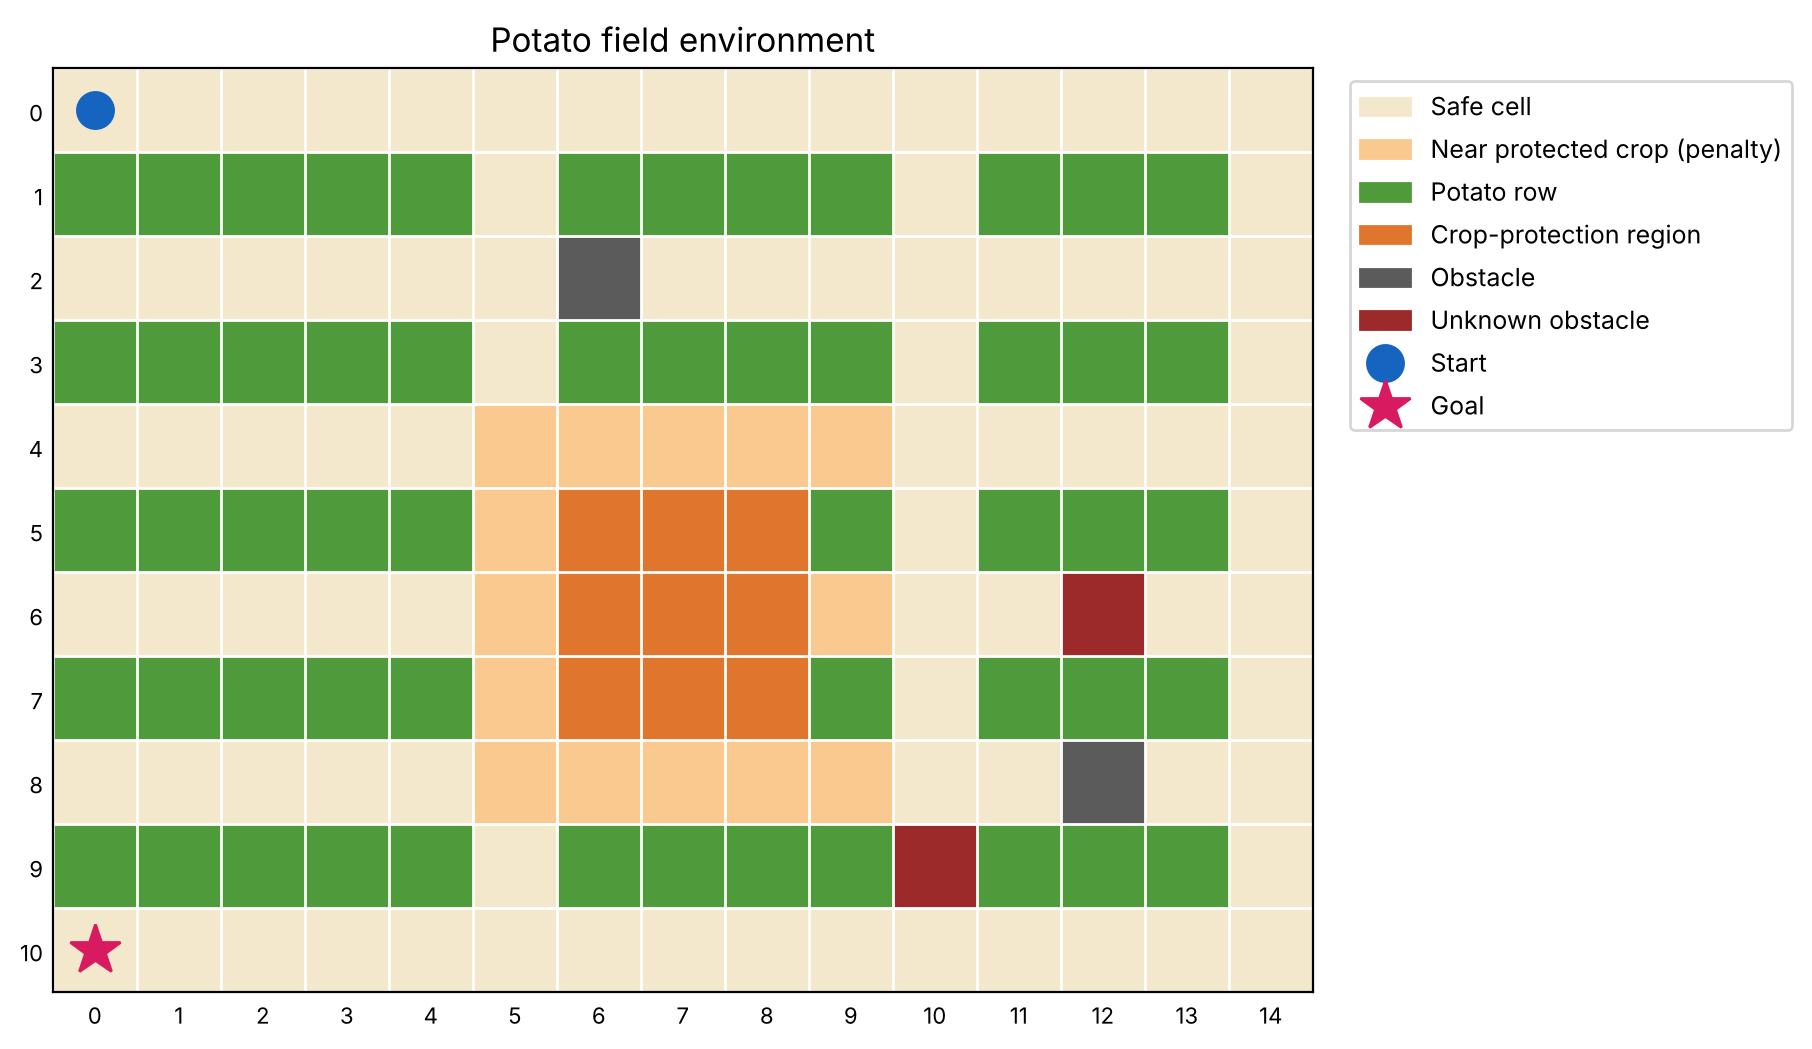

In [11]:
true_grid, start, goal = build_grid(FIELD_MAP, include_hidden=True)
known_grid, _, _ = build_grid(FIELD_MAP, include_hidden=False)
print(f"Field: {len(true_grid)} rows x {len(true_grid[0])} columns")
print(f"Start: {start}   Goal: {goal}   Step penalty near protected crops: +{PENALTY}")

fig, ax = plt.subplots(figsize=(10, 6))
draw_field(ax, FIELD_MAP, start, goal, "Potato field environment")
add_legend(ax)
plt.show()

### Experiment 1 – all obstacles known (Tasks 3 and 4)
Every algorithm plans once on the complete field.

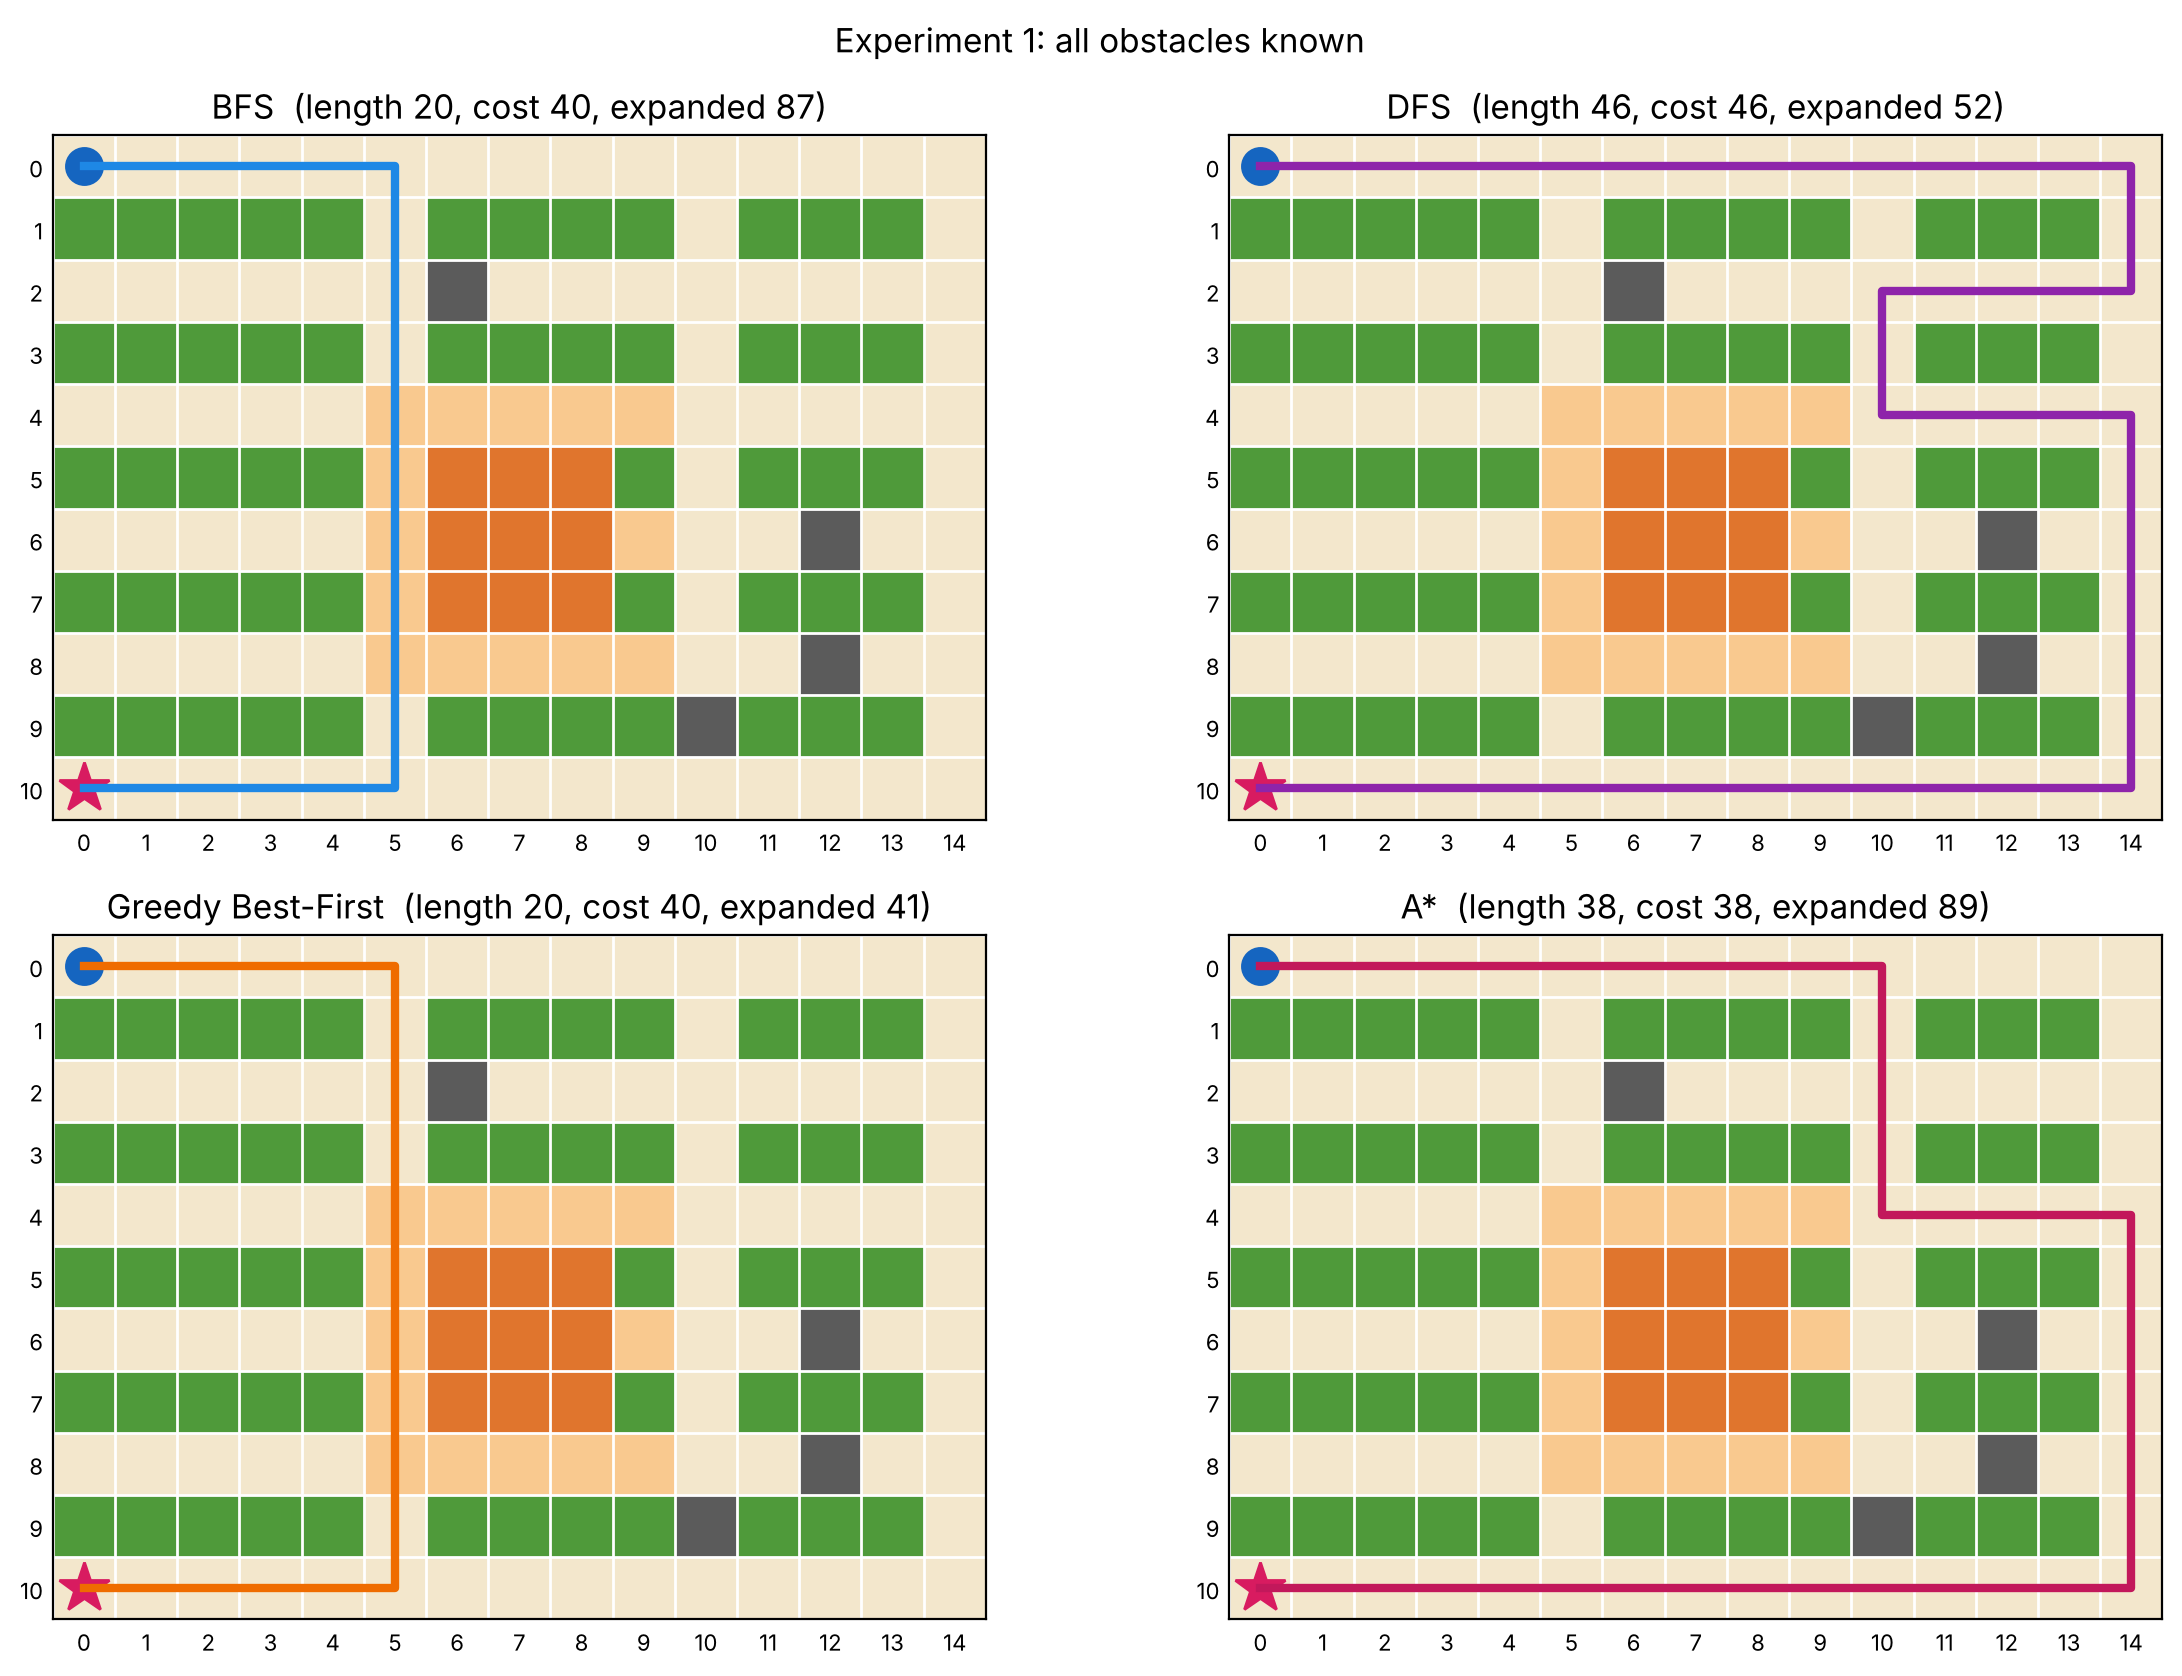

In [12]:
results = compare_algorithms(true_grid, start, goal)
rows = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
colours = ["#1e88e5", "#8e24aa", "#ef6c00", "#c2185b"]
for ax, colour, (name, path, expanded, ms) in zip(axes.flat, colours, results):
    row = make_row(name, true_grid, path, goal, expanded, ms)
    rows.append(row)
    draw_field(ax, true_grid, start, goal,
               f"{name}  (length {row[2]}, cost {row[3]}, expanded {expanded})")
    draw_path(ax, path, colour)
fig.suptitle("Experiment 1: all obstacles known")
fig.tight_layout()
plt.show()

### Experiment 2 – unknown obstacles, detection and replanning (Task 5)
The robot starts without knowing the two `X` obstacles.

  Robot at (8, 10) detected an unknown obstacle at (9, 10)
  Current route is blocked -> map updated, replanning with A*
  New route found: 24 moves to the goal
  Robot at (6, 11) detected an unknown obstacle at (6, 12)
  Current route is blocked -> map updated, replanning with A*
  New route found: 27 moves to the goal


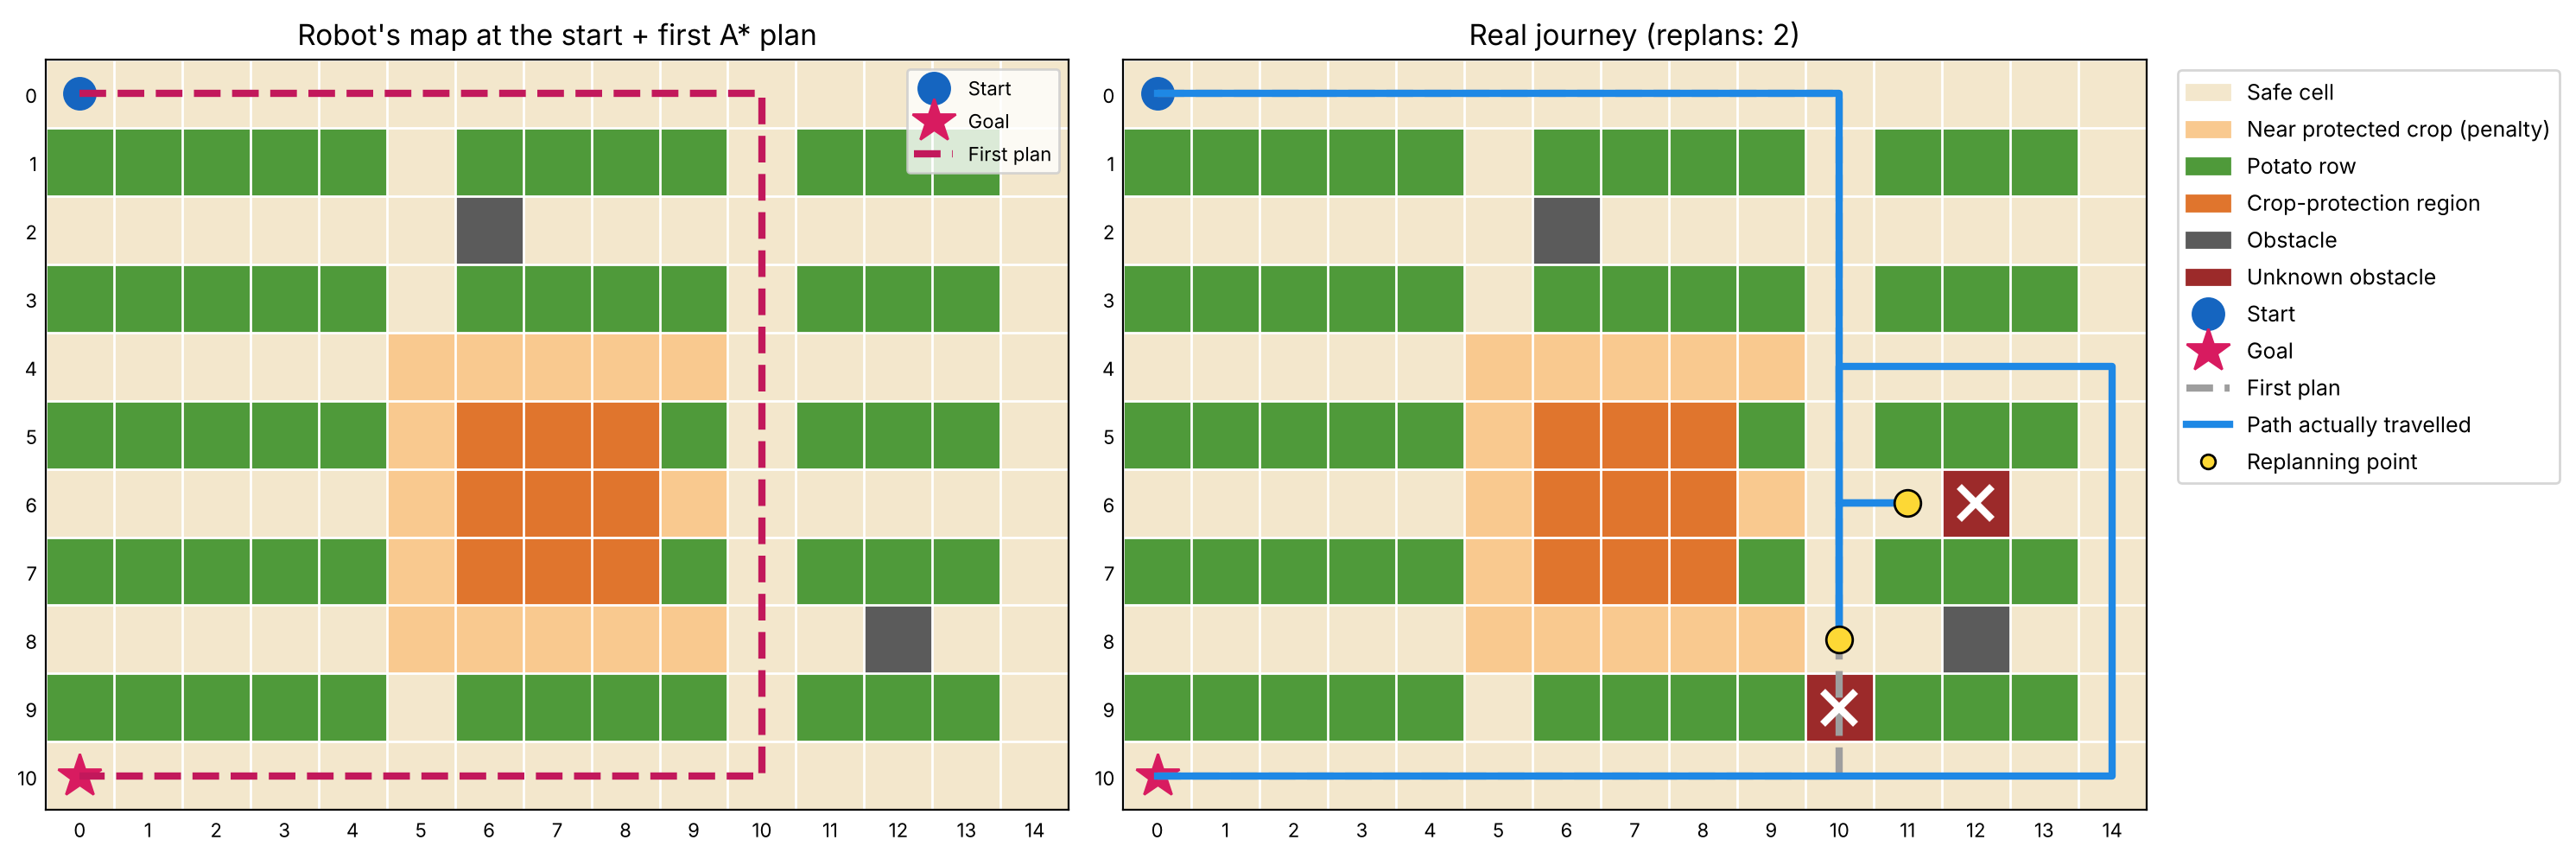

In [13]:
robot_map, _, _ = build_grid(FIELD_MAP, include_hidden=False)
t0 = time.perf_counter()
travelled, first_plan, detected, replan_points, expanded = navigate_with_replanning(
    robot_map, true_grid, start, goal)
ms = (time.perf_counter() - t0) * 1000
replans = len(replan_points)
rows.append(make_row("A* + replanning", true_grid, travelled, goal, expanded, ms, replans))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
draw_field(axes[0], known_grid, start, goal, "Robot's map at the start + first A* plan")
draw_path(axes[0], first_plan, "#c2185b", "--", "First plan")
axes[0].legend(loc="upper right", fontsize=8)
draw_field(axes[1], FIELD_MAP, start, goal, f"Real journey (replans: {replans})")
draw_path(axes[1], first_plan, "#9e9e9e", "--", "First plan")
draw_path(axes[1], travelled, "#1e88e5", "-", "Path actually travelled")
for r, c in detected:
    axes[1].plot(c, r, "x", color="white", markersize=14, markeredgewidth=3)
for r, c in replan_points:
    axes[1].plot(c, r, "o", color="#fdd835", markeredgecolor="black", markersize=11)
axes[1].plot([], [], "o", color="#fdd835", markeredgecolor="black", label="Replanning point")
add_legend(axes[1])
fig.tight_layout()
plt.show()

### Comparison table (Task 6)

In [14]:
print_table(rows)


Algorithm           Reached  Length  Cost   Expanded  Time (ms)  Replans
------------------------------------------------------------------------
BFS                 Yes      20      40     87        0.107      -
DFS                 Yes      46      46     52        0.047      -
Greedy Best-First   Yes      20      40     41        0.049      -
A*                  Yes      38      38     89        0.315      -
A* + replanning     Yes      48      48     157       0.788      2


### Observations
- **BFS** finds the fewest moves (20), but its route runs right beside the protected region (cost 40).
- **DFS** gives the longest route (46 moves). It just follows its neighbour order.
- **Greedy Best-First** expands the fewest nodes, but it takes the same risky route as BFS.
- **A\*** finds the lowest-cost, crop-safe route (cost 38). It is longer, but it never touches a caution cell.
- **With unknown obstacles**, the robot detects both, replans twice and still reaches the goal. It travels 48 moves instead of 38, because it has to backtrack.

Full discussion: see `RESULTS.md`. Times change slightly from run to run.